# 02 · Building the synthetic world

**Goal:** understand where the prices come from. We build a *miniature* generator step by step (one crop, one market), watch each
component change the price, and then compare our toy with the real generator's output.

Why bother? Because the data are synthetic, we know the truth. That lets us ask "did the model learn something real, or did it memorise noise?" -
a question you can never fully answer with real data.

The real generator is `src/agriprice/generator.py`; its equations are in `docs/generator_specification.md`.

In [1]:
from tutorial_utils import *
style()
rng = np.random.default_rng(7)
N, BURN = 156, 60
T = N + BURN
weeks = np.arange(1 - BURN, N + 1)
doy = ((START_DATE + pd.to_timedelta((weeks - 1) * 7 + 3, unit="D")).dayofyear).values.astype(float)

## Step 1 - a seasonal base price
Crops have harvest and lean seasons. A smooth annual cycle: price is *lowest* around the harvest peak (plenty of supply) and highest half a year later.
We work in **log prices**, so that effects are percentages.

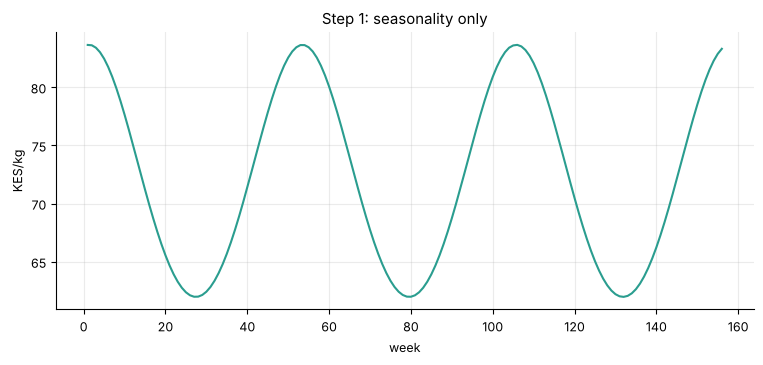

In [2]:
base, peak, amp = 72.0, 190, 0.15            # tomato-like: base KES/kg, harvest peak day-of-year, seasonal strength (log)
season = -amp * np.cos(2 * np.pi * (doy - peak) / 365.25)
fig, ax = plt.subplots()
ax.plot(weeks[BURN:], np.exp(np.log(base) + season[BURN:]), color="#2a9d8f")
ax.set_title("Step 1: seasonality only"); ax.set_xlabel("week"); ax.set_ylabel("KES/kg");

## Step 2 - persistence: prices have memory
Real prices do not jump around independently every week. We add a deviation `z` that **partially adjusts**: each week it keeps a share `phi`
of last week's deviation and gets a fresh random shock.

`z[t] = phi * z[t-1] + sigma * noise[t]`

`phi` close to 1 = long memory (storable goods such as maize); smaller `phi` = quick return to normal (perishable tomatoes).

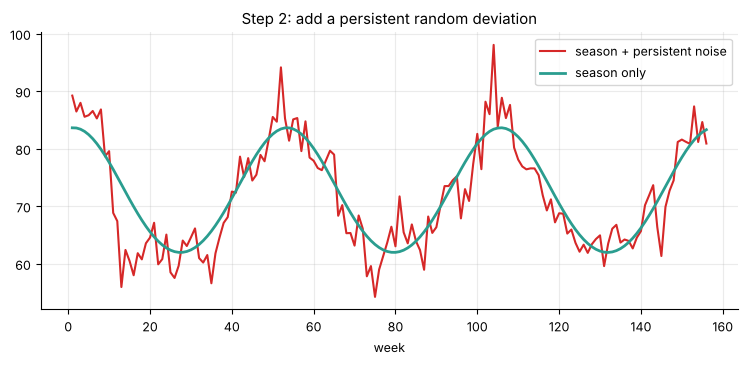

In [3]:
def simulate_ar(phi, sigma, n=T, rng=rng):
    z = np.zeros(n)
    for t in range(1, n):
        z[t] = phi * z[t - 1] + sigma * rng.standard_t(5) / np.sqrt(5 / 3)       # heavy-ish tails, unit variance
    return z

z = simulate_ar(0.55, 0.06)
fig, ax = plt.subplots()
ax.plot(weeks[BURN:], np.exp(np.log(base) + season + z)[BURN:], color="#d62828", label="season + persistent noise")
ax.plot(weeks[BURN:], np.exp(np.log(base) + season)[BURN:], color="#2a9d8f", lw=2, label="season only")
ax.legend(); ax.set_title("Step 2: add a persistent random deviation"); ax.set_xlabel("week");

## Step 3 - a driver: supply
When more produce arrives than expected, prices fall; when less arrives, they rise. We simulate a supply anomaly `s` (also persistent) and let the
price *adjust toward* a level implied by it: `z[t] = phi*z[t-1] + (1-phi)*beta*s[t] + noise`. With `beta < 0`, scarcity raises the price.
The `(1-phi)` factor means the *long-run* effect of a permanent supply anomaly is exactly `beta`.

correlation(supply anomaly, price deviation): -0.41 (negative: more supply, lower price)


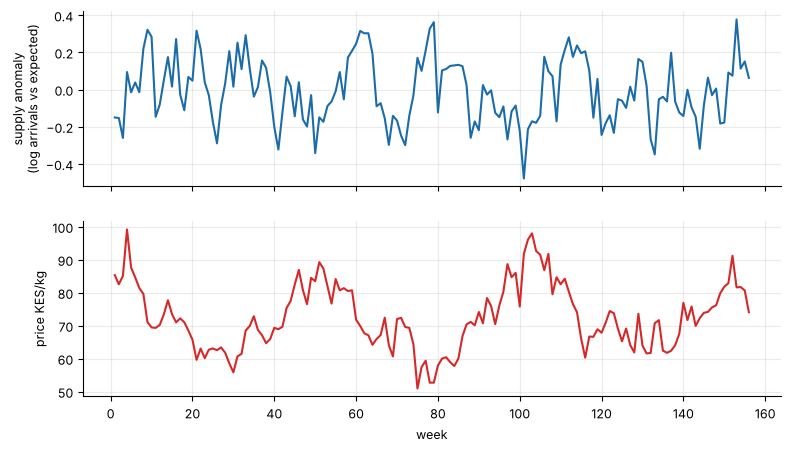

In [4]:
def simulate_supply(rho=0.6, sigma=0.18, n=T, rng=rng):
    s = np.zeros(n)
    for t in range(1, n):
        s[t] = rho * s[t - 1] + sigma * np.sqrt(1 - rho ** 2) * rng.normal()
    return s

def simulate_price(phi, sigma, beta, kappa=0.0, s=None, extra_target=0.0, seed=0):
    r = np.random.default_rng(seed)
    s = simulate_supply(rng=r) if s is None else s
    f = s * (1 + kappa * np.minimum(np.maximum(-s, 0), 0.6))          # scarcity hits harder than glut when kappa > 0
    z = np.zeros(T)
    for t in range(1, T):
        z[t] = phi * z[t - 1] + (1 - phi) * (beta * f[t] + extra_target * 1.0) + sigma * r.standard_t(5) / np.sqrt(5 / 3)
    return np.exp(np.log(base) + season + z), s, z

p3, s3, z3 = simulate_price(phi=0.55, sigma=0.06, beta=-0.36)
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(9, 5))
axes[0].plot(weeks[BURN:], s3[BURN:], color="#1b6ca8"); axes[0].set_ylabel("supply anomaly\n(log arrivals vs expected)")
axes[1].plot(weeks[BURN:], p3[BURN:], color="#d62828"); axes[1].set_ylabel("price KES/kg"); axes[1].set_xlabel("week")
print("correlation(supply anomaly, price deviation):", round(np.corrcoef(s3[BURN:], z3[BURN:])[0, 1], 2), "(negative: more supply, lower price)")

## Step 4 - nonlinearity: scarcity hurts more than glut helps
Real markets are asymmetric: a 30% shortage can double a price while a 30% glut cannot halve it. We reproduce this with `kappa > 0`.
This is one of the places where a **nonlinear model** (trees) could, in principle, beat a **linear** one (Ridge).

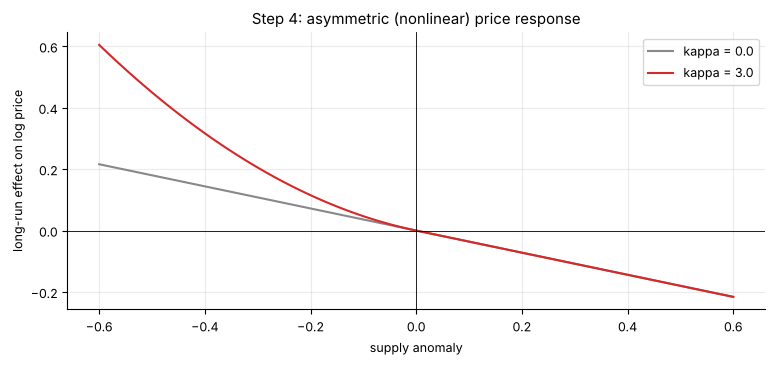

In [5]:
sgrid = np.linspace(-0.6, 0.6, 121)
for kappa, col in [(0.0, "#888"), (3.0, "#d62828")]:
    ax = plt.gca()
    ax.plot(sgrid, -0.36 * sgrid * (1 + kappa * np.minimum(np.maximum(-sgrid, 0), 0.6)), color=col, label=f"kappa = {kappa}")
plt.axhline(0, color="k", lw=.6); plt.axvline(0, color="k", lw=.6)
plt.xlabel("supply anomaly"); plt.ylabel("long-run effect on log price"); plt.title("Step 4: asymmetric (nonlinear) price response"); plt.legend();

## Step 5 - delayed causes: weather → future supply
Weather today does not change today's arrivals; it changes the harvest weeks later. In the real generator a rain deficit lowers arrivals with a crop-specific
delay (tomatoes ≈ 3 weeks, maize ≈ 10 weeks). Below, a 10-week drought is switched on in the toy world, and arrivals respond 3 weeks later.

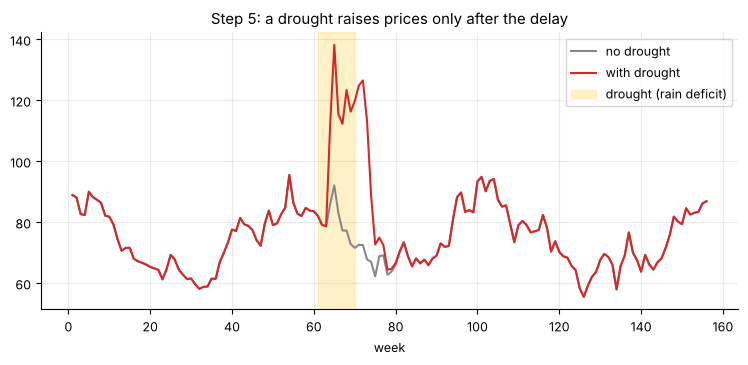

In [6]:
drought = np.zeros(T); drought[BURN + 60: BURN + 70] = 1.0                    # weeks 61-70 of the data
lag = 3
supply_effect = np.r_[np.zeros(lag), drought[:-lag]] * -0.5                    # arrivals fall `lag` weeks after the rain deficit
s5 = simulate_supply(rng=np.random.default_rng(1)) + supply_effect
p5, _, _ = simulate_price(0.55, 0.03, -0.36, kappa=3.0, s=s5, seed=1)
p5_no, _, _ = simulate_price(0.55, 0.03, -0.36, kappa=3.0, s=s5 - supply_effect, seed=1)
fig, ax = plt.subplots()
ax.plot(weeks[BURN:], p5_no[BURN:], color="#888", label="no drought")
ax.plot(weeks[BURN:], p5[BURN:], color="#d62828", label="with drought")
ax.axvspan(61, 70, color="#ffe8a3", alpha=.6, label="drought (rain deficit)")
ax.legend(); ax.set_title("Step 5: a drought raises prices only after the delay"); ax.set_xlabel("week");

**Why this matters for forecasting:** because the cause (rain) precedes the effect (price) by weeks, weather history has genuine *predictive* value
for future prices - exactly what the "E2 + weather" feature group tries to exploit. Contrast with *contemporaneous* supply: it moves the price the same week,
so at the forecast origin we only know its persistence, not next week's value.

## Step 6 - how fast do shocks fade? (perishable vs storable)

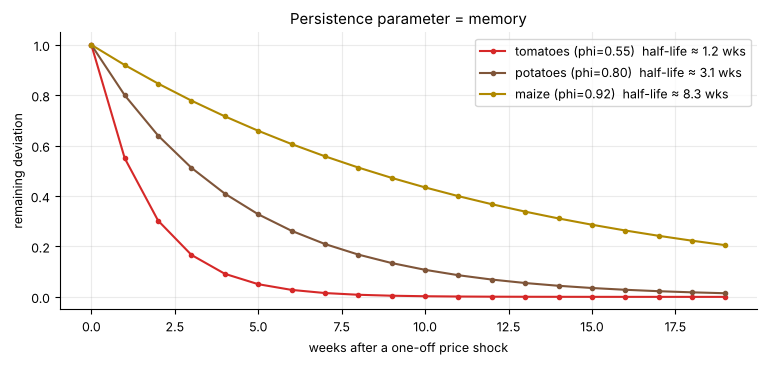

In [7]:
def impulse_response(phi, horizon=20):
    z = np.zeros(horizon); z[0] = 1.0
    for t in range(1, horizon):
        z[t] = phi * z[t - 1]
    return z

fig, ax = plt.subplots()
for name, phi, col in [("tomatoes (phi=0.55)", 0.55, "#d62828"), ("potatoes (phi=0.80)", 0.80, "#7f5539"), ("maize (phi=0.92)", 0.92, "#b08900")]:
    ax.plot(impulse_response(phi), marker="o", ms=3, color=col, label=f"{name}  half-life ≈ {np.log(.5)/np.log(phi):.1f} wks")
ax.set_xlabel("weeks after a one-off price shock"); ax.set_ylabel("remaining deviation"); ax.legend(); ax.set_title("Persistence parameter = memory");

## Compare the toy with the real generator
The shipped file `data/clean_world_audit.csv` is the real generator's output before any data-quality problems. We compare a few *summary properties* of
the real tomato and maize series with toy series that use the real parameters.

In [8]:
world = pd.read_csv(DATA / "clean_world_audit.csv")
world["series"] = world.market_id + "|" + world.crop_id
lw = wide(world, "latent_price_kes_kg")
def props(x):
    x = np.log(np.asarray(x)); d = np.diff(x); xc = x - x.mean()
    return dict(weekly_change_sd=d.std(), level_acf1=(xc[1:] * xc[:-1]).sum() / (xc ** 2).sum(), change_acf1=np.corrcoef(d[1:], d[:-1])[0, 1])
rows = {"real tomatoes (Nairobi)": props(lw["MKT-01|CRP-02"]), "real maize (Nairobi)": props(lw["MKT-01|CRP-01"])}
pt, _, _ = simulate_price(0.55, 0.06, -0.36, kappa=3.0, seed=3); pm, _, _ = simulate_price(0.92, 0.014, -0.16, kappa=1.5, seed=3)
rows["toy tomatoes"] = props(pt[BURN:]); rows["toy maize"] = props(pm[BURN:])
pd.DataFrame(rows).T.round(3)

,weekly_change_sd,level_acf1,change_acf1
real tomatoes (Nairobi),0.089,0.881,0.035
real maize (Nairobi),0.018,0.979,0.255
toy tomatoes,0.086,0.862,-0.101
toy maize,0.021,0.976,0.425


The toy is far simpler (no demand, transport, weather or markets), yet it reproduces the *character* of each crop: the weekly volatility and the long memory of the price *level*
match well (tomatoes about 9% weekly moves, level autocorrelation 0.86-0.88; maize about 2%, 0.98). It does **not** match the autocorrelation of weekly *changes*
(toy tomatoes -0.10 vs real +0.04; toy maize 0.43 vs 0.26): in the toy the only source of memory is the AR term, which makes changes mean-revert; in the real generator persistent drivers
(supply, demand, neighbouring markets) add momentum. A toy is good for seeing which ingredient causes which feature - and for noticing where it is too simple.

## The real events
The real generator also injects 16 **documented events** (gluts, droughts, floods, fuel step, demand surges, import shocks, a source-market disruption and a lasting
transport-cost shift). They are listed in `data/events_schedule.csv`, with the partition (train / validation / test) in which they occur.

In [9]:
ev = pd.read_csv(DATA / "events_schedule.csv")
ev[["event_id", "event_type", "start_week", "end_week", "intensity", "partition", "new_in_test"]]

,event_id,event_type,start_week,end_week,intensity,partition,new_in_test
0,EV01,harvest_glut,38,42,0.60,train,False
1,EV02,harvest_glut,70,72,0.80,train,False
2,EV03,drought,55,62,0.70,train,False
3,EV04,flood,16,18,1.00,train,False
4,EV05,fuel_step,85,85,0.25,train,False
5,EV06,demand_surge,49,51,0.25,train,False
6,EV07,import_supply_shock,90,93,0.50,train,False
7,EV08,cross_market_disruption,112,115,0.60,validation,False
8,EV09,demand_surge,118,120,0.30,validation,False
9,EV10,flood,121,123,0.80,validation,False


Three design choices to notice:
* Four test-window events are **new or stronger** than anything in training (`new_in_test = True`), so the test is a real stress test.
* EV13 is a *regime shift*: transport costs stay 35% higher for the rest of the data. No training row contains this cause.
* Events are documented in separate columns (`event_ids`, `event_affected`), not mixed into `data_quality_flag` - so cleaning rules cannot erase real market behaviour.

**Check that an event really did what it claims** (the generator's acceptance tests do this for all 16): during the strong test drought EV12 rainfall in the affected markets should be far below normal.

In [10]:
ev12 = ev[ev.event_id == "EV12"].iloc[0]
rain = wide(world, "rainfall_mm")
affected = [f"{m}|CRP-01" for m in ev12.markets.split("|")]
during = rain[affected].loc[ev12.start_week:ev12.end_week].mean()
normal = rain[affected].median()
print(pd.DataFrame({"mean rain during EV12": during, "typical weekly rain": normal, "ratio": during / normal}).round(2))

               mean rain during EV12  typical weekly rain  ratio
series                                                          
MKT-02|CRP-01                   3.37                15.06   0.22
MKT-03|CRP-01                   4.49                17.05   0.26
MKT-04|CRP-01                   4.31                17.76   0.24


## Exercises
1. In Step 3, set `beta = 0`. What happens to the correlation printed below the plot? What would a forecaster gain from supply data in that world?
2. In Step 5, change `lag` from 3 to 10 (maize-like). At a forecast origin in the middle of the drought, how many weeks of "warning" does the rain data give?
3. Build a *second* market whose deviation also depends on the first market's previous-week deviation (`z_B[t] += delta * z_A[t-1]`). Plot both. This is the idea behind the one-week-lag cross-market transmission, which turns out to be the most useful external information in notebook 08.
4. Make `phi = 1.0`. What goes wrong (hint: the series is no longer stationary)? Why does the real generator use `phi < 1`?

**Where this lives in the pipeline:** `src/agriprice/generator.py` (`generate_clean_world`), parameters in `config/experiment_config.yaml`,
acceptance checks in `src/agriprice/validate.py`.